Preamble

In [1]:
import numpy as np 
import pandas 
import matplotlib
import matplotlib.pyplot as plt
Data = pandas.read_csv("data.csv")


MADS

DAVID

In [2]:
# Create the dummy as a column in Data
Data["madsk"] = (Data["past_employment"] > 3).astype(int)
Data["past_employment^2"] = Data["past_employment"] ** 2
Data["past_employment^3"] = Data["past_employment"] ** 3
import statsmodels.formula.api as smf

# Estimate the regression
regression = smf.ols(
    "ui_duration ~ madsk * (past_employment + I(past_employment**2) + I(past_employment**3))",
    data=Data
).fit()

print(regression.summary())

# Save fitted values
Data["predicted_ui_duration"] = regression.predict(Data)

# Create bins
Data["employment_bin"] = pandas.cut(
    Data["past_employment"],
    bins=30
)

# Collapse into bin means
binned_data = (
    Data
    .groupby(["employment_bin", "madsk"], observed=True)
    .agg(
        past_employment=("past_employment", "mean"),
        ui_duration=("ui_duration", "mean")
    )
    .reset_index()
)

display(binned_data.head())

                            OLS Regression Results                            
Dep. Variable:            ui_duration   R-squared:                       0.968
Model:                            OLS   Adj. R-squared:                  0.968
Method:                 Least Squares   F-statistic:                 8.774e+05
Date:                Mon, 16 Nov 2026   Prob (F-statistic):               0.00
Time:                        10:52:46   Log-Likelihood:                 55570.
No. Observations:              200000   AIC:                        -1.111e+05
Df Residuals:                  199992   BIC:                        -1.110e+05
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
Intercept     

,employment_bin,madsk,past_employment,ui_duration
0,"(0.0186, 0.224]",0,0.163223,5.076241
1,"(0.224, 0.423]",0,0.330854,4.625194
2,"(0.423, 0.622]",0,0.523327,4.161642
3,"(0.622, 0.821]",0,0.720288,3.744232
4,"(0.821, 1.02]",0,0.920041,3.373754


C:\Users\madsh\AppData\Local\Temp\ipykernel_46380\2763936192.py:49: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


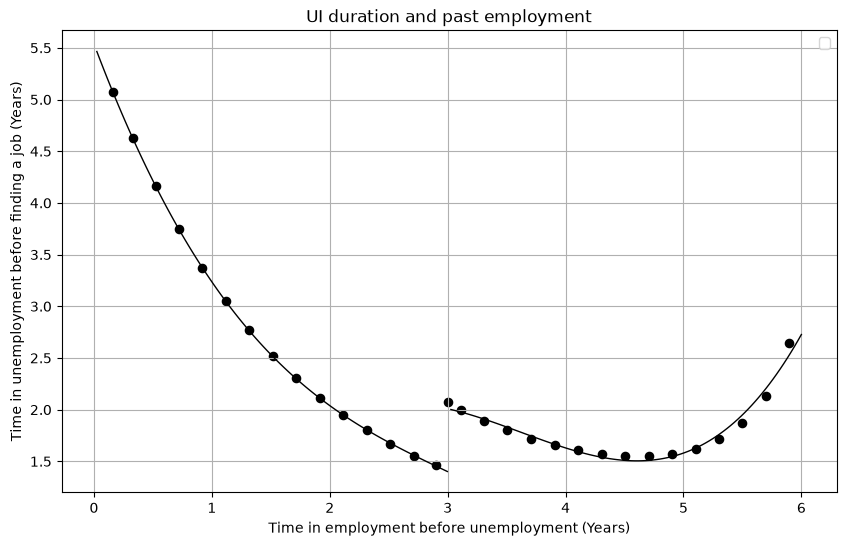

In [3]:
plt.figure(figsize=(10, 6))

# Binned means as dots
for dummy_value in sorted(binned_data["madsk"].unique()):
    subset = binned_data[binned_data["madsk"] == dummy_value]

    plt.scatter(
        subset["past_employment"],
        subset["ui_duration"],
        color="black",
        s=35,
    )

# Smooth prediction grid
employment_grid = np.linspace(
    Data["past_employment"].min(),
    Data["past_employment"].max(),
    200
)

# Regression predictions
for dummy_value in sorted(Data["madsk"].unique()):

    if dummy_value == 0:
        employment_grid_cut = employment_grid[employment_grid <= 3]
    else:
        employment_grid_cut = employment_grid[employment_grid >= 3]

    prediction_data = pandas.DataFrame({
        "past_employment": employment_grid_cut,
        "madsk": dummy_value
    })

    prediction_data["predicted_ui_duration"] = regression.predict(
        prediction_data
    )

    plt.plot(
        prediction_data["past_employment"],
        prediction_data["predicted_ui_duration"],
        linewidth=1,
        color="black",
    )

plt.xlabel("Time in employment before unemployment (Years)")
plt.ylabel("Time in unemployment before finding a job (Years)")
plt.title("UI duration and past employment")
plt.grid(True)
plt.legend()
plt.show()

In [12]:
#Isolating effect:
#first we use the most correct approach 
# by subtracting the estimated effect of the dummy variable from the predicted values for the group with madsk=1.
threshold_data = pandas.DataFrame({
    "past_employment": [2.9999, 3.0001],
    "madsk": [0, 1]
})

threshold_predictions = regression.predict(threshold_data)

effect_at_threshold = (
    threshold_predictions.iloc[1] - threshold_predictions.iloc[0]
)

print("Predicted value just below 3:", threshold_predictions.iloc[0])
print("Predicted value just above 3:", threshold_predictions.iloc[1])
print("Estimated threshold effect:", effect_at_threshold)


# Keep observations within 0.1 of the threshold
threshold_data = Data[
    Data["past_employment"].between(2.9, 3.1)
].copy()

# Define bins [2.9, 3.0) and [3.0, 3.1)
threshold_data["threshold_bin"] = pandas.cut(
    threshold_data["past_employment"],
    bins=[2.9, 3.0, 3.1],
    labels=["Below 3", "Above 3"],
    right=False
)

# Calculate the mean in each bin
threshold_means = (
    threshold_data
    .groupby("threshold_bin", observed=True)
    .agg(
        mean_ui_duration=("ui_duration", "mean"),
        number_of_observations=("ui_duration", "size")
    )
    .reset_index()
)

display(threshold_means)

# Difference: bin above 3 minus bin below 3
threshold_effect = (
    threshold_means.loc[
        threshold_means["threshold_bin"] == "Above 3",
        "mean_ui_duration"
    ].iloc[0]
    -
    threshold_means.loc[
        threshold_means["threshold_bin"] == "Below 3",
        "mean_ui_duration"
    ].iloc[0]
)

print("Difference between the two 0.1-wide bins:", threshold_effect)

Predicted value just below 3: 1.4005060175249304
Predicted value just above 3: 2.008659976853056
Estimated threshold effect: 0.6081539593281255


,threshold_bin,mean_ui_duration,number_of_observations
0,Below 3,1.442718,2673
1,Above 3,2.043294,2614


Difference between the two 0.1-wide bins: 0.6005756637262418
